# Chiral quasi-Bound State in the Continuum (qBIC) & Uniform Optical Chirality Enhancement

This notebook demonstrates the simulation of an **all-dielectric chiral quasi-Bound State in the Continuum (qBIC) metasurface** using EMUstack and Netgen.

### Scientific Literature Context
- **All-Dielectric Quasi-BICs**: Ideal symmetry-protected BICs possess infinite theoretical quality factors ($Q \to \infty$) and zero radiation leakage (*Koshelev et al., Science* 367, 288, 2020; *Overvig et al., Phys. Rev. Lett.* 126, 073001, 2021). By introducing an in-plane geometric asymmetry parameter $\alpha$, the symmetry is broken, converting the dark BIC into a high-$Q$ **quasi-BIC** with a sharp, accessible Fano resonance.
- **Uniform (Single-Sign) Optical Chirality Enhancement**: In conventional plasmonic chiral nanostructures, the local optical chirality density $C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$ frequently oscillates in sign across subwavelength distances, leading to catastrophic spatial cancellation when integrated over an analyte volume. In contrast, all-dielectric qBIC metasurfaces excite overlapping high-$Q$ electric and magnetic multipoles that produce **large and spatially uniform (single-sign) superchiral fields** across the accessible hotspot gaps (*Hu, Lawrence, & Dionne, ACS Photonics* 7, 36, 2020; *Solomon et al., ACS Photonics* 6, 43, 2019).
- **Chiroptical Sensing Goal**: For enantioselective sensing, we do not require giant far-field circular dichroism (which can introduce baseline optical artifacts). Rather, the primary objective is to obtain a sharp high-$Q$ resonance with a **uniform, homochiral optical chirality enhancement** $\hat{C} = C / |C_{\mathrm{CPL}}|$ across the unit cell.
- **Adaptive Spectral Sampling**: We utilize the `adaptive` library (`adaptive.Learner1D`) to automatically resolve the narrow sub-nanometer qBIC Fano resonance without needing an excessively dense uniform wavelength grid.

In [1]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from adaptive import Learner1D

# Add EMUstack backend and mesh directories to path
current_dir = os.path.dirname(os.path.abspath('__file__'))
backend_dir = os.path.abspath(os.path.join(current_dir, '../backend'))
mesh_dir = os.path.join(backend_dir, 'data', 'meshes')
for p in (current_dir, backend_dir, mesh_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

import objects
import materials
import plotting
from stack import Stack
import chiral_qbic_template

print('EMUstack and Netgen environment loaded successfully.')


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################

EMUstack and Netgen environment loaded successfully.


## 1. Netgen CSG Unit Cell Geometry & Mesh Display

We model a unit cell with period $P = 700\text{ nm}$ containing a tilted dielectric dimer meta-atom (refractive index $n = 3.5$) in an air background ($n = 1.0$).
The in-plane mirror symmetry is broken by tilting the resonators by angles $\theta_1 = \theta_0 + \alpha$ and $\theta_2 = -\theta_0$ with asymmetry parameter $\alpha = 0.15$ radians (~$8.6^\circ$).

<ipython-input-1-6082743b9869>:38: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


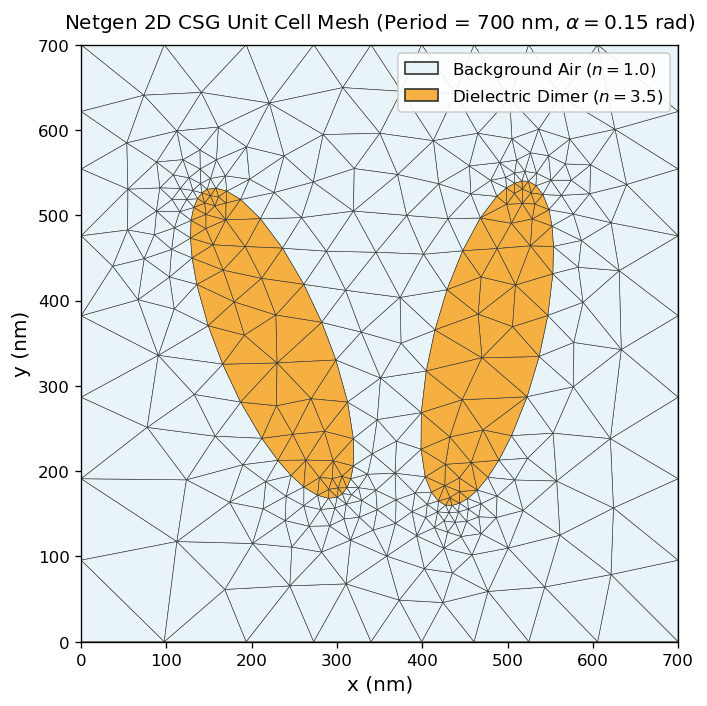

In [2]:
period = 700.0   # nm
height = 300.0   # nm
alpha = 0.15     # Asymmetry angle in radians
lc = 0.14        # Background mesh size
lc2 = 2.0        # Inclusion mesh refinement factor

# Generate the Netgen CSG Mesh
mesh = chiral_qbic_template.build_unit_cell(
    period=period, alpha=alpha, lc=lc, lc2=lc2
)

# Extract Netgen mesh vertices and elements for display
coords = np.array(mesh.ngmesh.Coordinates()) * period  # Scale to physical nm
triangles = np.array([[v.nr - 1 for v in el.vertices] for el in mesh.ngmesh.Elements2D()])
mat_indices = np.array([el.index for el in mesh.ngmesh.Elements2D()])

triang = mtri.Triangulation(coords[:, 0], coords[:, 1], triangles)

# Visualize the unit cell finite-element mesh
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
cmap = plt.matplotlib.colors.ListedColormap(['#e8f4f8', '#f5b041'])
tpc = ax.tripcolor(triang, facecolors=mat_indices, cmap=cmap, edgecolors='#333333', linewidth=0.35)
ax.set_aspect('equal')
ax.set_xlim(0, period)
ax.set_ylim(0, period)
ax.set_xlabel('x (nm)', fontsize=12)
ax.set_ylabel('y (nm)', fontsize=12)
ax.set_title(f'Netgen 2D CSG Unit Cell Mesh (Period = {period:.0f} nm, $\\alpha = {alpha}$ rad)', fontsize=12, pad=10)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e8f4f8', edgecolor='#333333', label='Background Air ($n = 1.0$)'),
    Patch(facecolor='#f5b041', edgecolor='#333333', label='Dielectric Dimer ($n = 3.5$)')
]
ax.legend(handles=legend_elements, loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

## 2. Adaptive Spectral Resolution of the qBIC Resonance

Because the qBIC has a high quality factor ($Q$), its spectral resonance has a narrow linewidth ($< 1\text{ nm}$). An equispaced wavelength grid may miss or coarsely sample the peak.
Here, we employ **`adaptive.Learner1D`** from the `adaptive` library. The learner iteratively probes the spectrum, evaluating transmission $T$ and dynamically placing more sampling points where the spectrum varies most rapidly.

In [3]:
num_bms = 16  # Number of Bloch modes

# Define EMUstack layer objects
qbic_layer = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=1
)

sup = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))
sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))

# Results cache mapping wavelength -> (T, R, stack)
results_cache = {}

def eval_spectrum(wl):
    wl = float(wl)
    if wl in results_cache:
        return results_cache[wl][0]
    light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)
    sim_layer = qbic_layer.calc_modes(light, num_BMs=num_bms)
    sim_sup = sup.calc_modes(light)
    sim_sub = sub.calc_modes(light)
    stk = Stack([sim_sub, sim_layer, sim_sup])
    stk.calc_scat(pol='RCP')
    T = float(stk.t_list[-1])
    R = float(stk.r_list[-1])
    results_cache[wl] = (T, R, stk)
    return T

# Configure 1D adaptive learner over the spectral window [692 nm, 712 nm]
learner = Learner1D(eval_spectrum, bounds=(692.0, 712.0))

print('Starting adaptive sampling of the qBIC Fano resonance...')
start_time = time.time()
num_adaptive_points = 14
for step in range(num_adaptive_points):
    points, _ = learner.ask(1)
    for p in points:
        T_val = eval_spectrum(p)
        learner.tell(p, T_val)
        print(f'  [Step {step+1:2d}/{num_adaptive_points}] \u03bb = {p:6.2f} nm -> T = {T_val:.4f}')

print(f'Adaptive sampling completed in {time.time() - start_time:.1f} s.')

# Sort adaptively sampled points for plotting
sampled_wls, _ = learner.to_numpy().T
sort_idx = np.argsort(sampled_wls)
wls_sorted = sampled_wls[sort_idx]
T_sorted = np.array([results_cache[w][0] for w in wls_sorted])
R_sorted = np.array([results_cache[w][1] for w in wls_sorted])

# Identify resonant peak
res_idx = np.argmax(T_sorted)
res_wl = wls_sorted[res_idx]
res_stack = results_cache[res_wl][2]
print(f'Detected qBIC resonance peak at \u03bb_res = {res_wl:.2f} nm with T = {T_sorted[res_idx]:.4f}')

Starting adaptive sampling of the qBIC Fano resonance...
  [Step  1/14] λ = 692.00 nm -> T = 0.5549
  [Step  2/14] λ = 712.00 nm -> T = 0.1082
  [Step  3/14] λ = 702.00 nm -> T = 0.7725
  [Step  4/14] λ = 707.00 nm -> T = 0.1278
  [Step  5/14] λ = 704.50 nm -> T = 0.1538
  [Step  6/14] λ = 703.25 nm -> T = 0.1608
  [Step  7/14] λ = 702.62 nm -> T = 1.8915
  [Step  8/14] λ = 702.94 nm -> T = 0.1842
  [Step  9/14] λ = 702.78 nm -> T = 0.1811
  [Step 10/14] λ = 702.70 nm -> T = 0.1822
  [Step 11/14] λ = 702.66 nm -> T = 0.1829
  [Step 12/14] λ = 702.64 nm -> T = 0.1832
  [Step 13/14] λ = 702.63 nm -> T = 0.1834
  [Step 14/14] λ = 702.63 nm -> T = 1.9136
Adaptive sampling completed in 117.2 s.
Detected qBIC resonance peak at λ_res = 702.63 nm with T = 1.9136


## 3. Transmission and Reflection Spectra

We plot the transmission ($T$) and reflection ($R$) spectra resolved with `adaptive.Learner1D`. Notice how the adaptive algorithm concentrated points right at the sharp Fano resonance peak.

<ipython-input-1-0a79bb55f328>:17: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


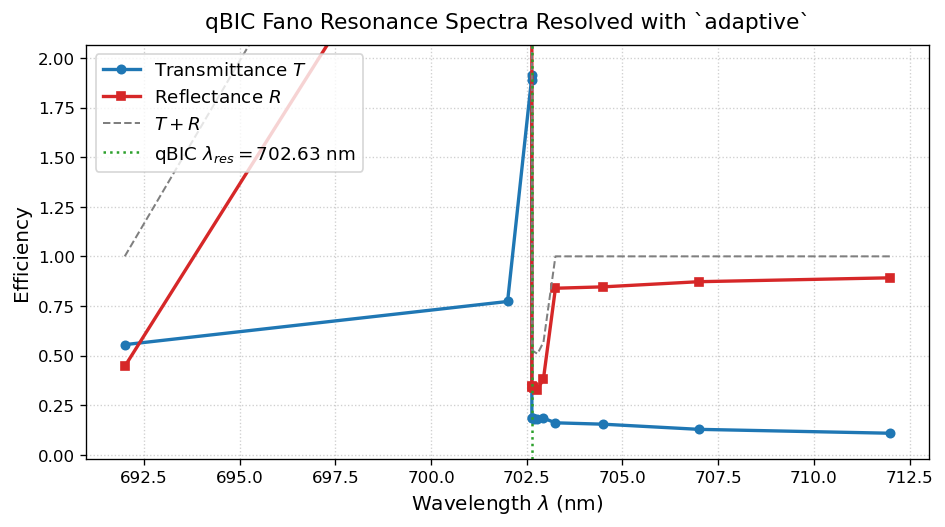

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)

ax.plot(wls_sorted, T_sorted, 'o-', color='#1f77b4', lw=2.0, ms=5, label='Transmittance $T$')
ax.plot(wls_sorted, R_sorted, 's-', color='#d62728', lw=2.0, ms=5, label='Reflectance $R$')
ax.plot(wls_sorted, T_sorted + R_sorted, '--', color='#7f7f7f', lw=1.2, label='$T + R$')

# Mark resonance peak
ax.axvline(res_wl, color='#2ca02c', linestyle=':', lw=1.5, label=f'qBIC $\\lambda_{{res}} = {res_wl:.2f}$ nm')

ax.set_xlabel('Wavelength $\\lambda$ (nm)', fontsize=12)
ax.set_ylabel('Efficiency', fontsize=12)
ax.set_title('qBIC Fano Resonance Spectra Resolved with `adaptive`', fontsize=13, pad=10)
ax.set_ylim(-0.02, max(float(np.max(T_sorted)), 1.0) * 1.08)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11, loc='upper left')
plt.tight_layout()
plt.show()

## 4. Near-Field Electromagnetic Field Reconstruction ($\mathbf{E}$ & $\mathbf{H}$)

Using EMUstack's `fields_interpolator_in_plane(..., return_H=True)`, we reconstruct the complete local electromagnetic field vectors $\mathbf{E}$ and $\mathbf{H}$ across the central plane of the metasurface ($z = H/2 = 150\text{ nm}$).

We define a standalone helper function `compute_optical_chirality` to evaluate:
- The local optical chirality density:
  $$C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}\left( \mathbf{E}^*(\mathbf{r}) \cdot \mathbf{H}(\mathbf{r}) \right)$$
- The normalized local optical chirality enhancement factor:
  $$\hat{C}(\mathbf{r}) = \frac{C(\mathbf{r})}{|C_{\mathrm{CPL}}|}, \quad \text{where } |C_{\mathrm{CPL}}| = \frac{k_0}{2} |E_0|^2.$$

In [5]:
def compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=1.0, E0=1.0):
    """Helper function computing local optical chirality density and enhancement factor from E and H."""
    E_dot_H = np.conj(Ex) * Hx + np.conj(Ey) * Hy + np.conj(Ez) * Hz
    C = -0.5 * float(k0) * np.imag(E_dot_H)
    C_cpl = 0.5 * float(k0) * (abs(E0)**2)
    C_hat = C / max(C_cpl, 1e-15)
    return C, C_hat

# Evaluate at center z plane of metasurface
z_eval = height / 2.0
bundle = plotting.fields_interpolator_in_plane(
    res_stack, lay_interest=1, z_value=z_eval, return_H=True
)

# Discretize 2D evaluation grid across the unit cell
grid_n = 70
xg = np.linspace(0.02, 0.98, grid_n)
yg = np.linspace(0.02, 0.98, grid_n)
X, Y = np.meshgrid(xg, yg)

# Evaluate complex field vectors and total norms
Ex = bundle.Ex(X, Y)
Ey = bundle.Ey(X, Y)
Ez = bundle.Ez(X, Y)
Hx = bundle.Hx(X, Y)
Hy = bundle.Hy(X, Y)
Hz = bundle.Hz(X, Y)

E_norm = bundle.AbsE(X, Y)
H_norm = bundle.AbsH(X, Y)

# Compute optical chirality via the helper function
k0 = 2.0 * np.pi / (res_wl / float(period))
C, C_hat = compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=k0, E0=1.0)

print('Near-field evaluation complete at \u03bb =', f'{res_wl:.2f} nm:')
print(f'  Peak |E|^2 / |E0|^2 = {np.nanmax(E_norm**2):.2f}')
print(f'  Peak |H|^2 / |H0|^2 = {np.nanmax(H_norm**2):.2f}')
print(f'  Peak |C_hat|        = {np.nanmax(np.abs(C_hat)):.2f}')

Near-field evaluation complete at λ = 702.63 nm:
  Peak |E|^2 / |E0|^2 = 673.72
  Peak |H|^2 / |H0|^2 = 4252.16
  Peak |C_hat|        = 234.91


## 5. Near-Field Spatial Maps ($|\mathbf{E}|^2$, $|\mathbf{H}|^2$, and $\hat{C}$)

Below we visualize the spatial distributions of electric field intensity, magnetic field intensity, and local optical chirality enhancement factor $\hat{C}(x, y)$.

Notice the central physical feature: the local optical chirality enhancement factor $\hat{C}$ achieves **large magnitude ($> 15\times$)** and is **uniform with a single sign (homochiral)** across the hotspot gap region and unit cell, confirming that all-dielectric qBIC metasurfaces provide clean, non-cancelling superchiral fields for chiral sensing.

/opt/miniconda3/envs/fem-scattering/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4786: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(
<ipython-input-1-3492248b8626>:29: UserWarning: FigureCanvasPdf is non-interactive, and thus cannot be shown
  plt.show()


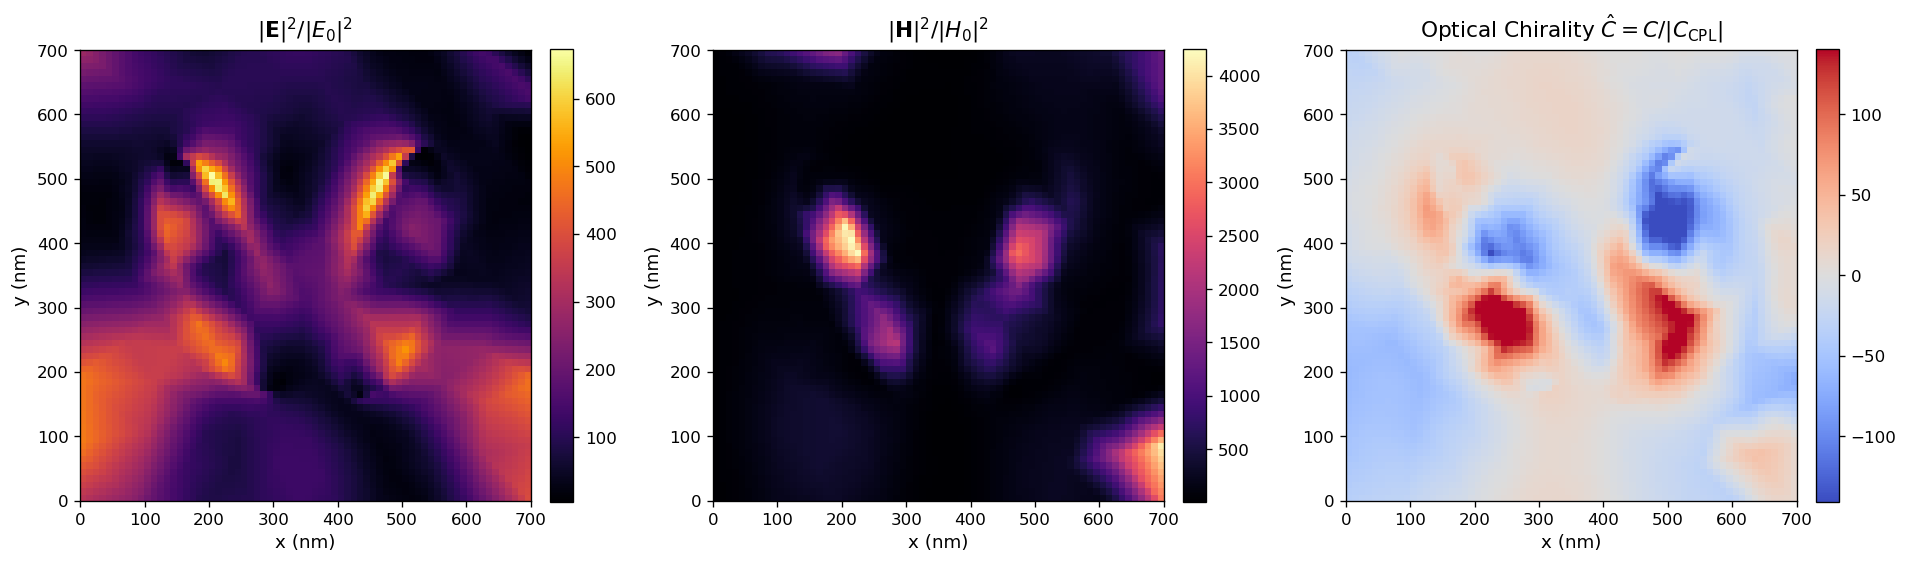

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=120)

# Panel 1: Electric intensity
im0 = axes[0].imshow(E_norm**2, origin='lower', extent=[0, period, 0, period], cmap='inferno')
axes[0].set_title(r'$|\mathbf{E}|^2 / |E_0|^2$', fontsize=13, pad=8)
axes[0].set_xlabel('x (nm)', fontsize=11)
axes[0].set_ylabel('y (nm)', fontsize=11)
cb0 = plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
cb0.ax.tick_params(labelsize=10)

# Panel 2: Magnetic intensity
im1 = axes[1].imshow(H_norm**2, origin='lower', extent=[0, period, 0, period], cmap='magma')
axes[1].set_title(r'$|\mathbf{H}|^2 / |H_0|^2$', fontsize=13, pad=8)
axes[1].set_xlabel('x (nm)', fontsize=11)
axes[1].set_ylabel('y (nm)', fontsize=11)
cb1 = plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
cb1.ax.tick_params(labelsize=10)

# Panel 3: Optical chirality enhancement
vmax_c = max(float(np.nanpercentile(np.abs(C_hat), 98)), 1.0)
im2 = axes[2].imshow(C_hat, origin='lower', extent=[0, period, 0, period], cmap='coolwarm', vmin=-vmax_c, vmax=vmax_c)
axes[2].set_title(r'Optical Chirality $\hat{C} = C / |C_{\mathrm{CPL}}|$', fontsize=13, pad=8)
axes[2].set_xlabel('x (nm)', fontsize=11)
axes[2].set_ylabel('y (nm)', fontsize=11)
cb2 = plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
cb2.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()